# Engineering-grade, leakage-resistant WDBC pipeline

**Target venue:** Springer Nature / BMC Medical Informatics and Decision Making  
**Scope:** internal model development and locked internal evaluation; no claim of external validation or clinical deployment.  
**Quality gates implemented:** immutable holdout, repeated nested CV, fold-local preprocessing and oversampling, leakage-resistant stacking, fold-local calibration for every benchmark candidate, fully cross-fitted threshold selection, dependence-aware comparisons, exact and bootstrap uncertainty, fidelity-gated explanations, deterministic manifests, and machine-verifiable integrity tests.

> Full mode is publication mode. For a short Colab smoke test, set the environment variable `WDBC_QUICK_MODE=1` before the configuration cell. Quick-mode results must never be reported in a manuscript.


In [1]:
# 0. Pinned dependencies for Google Colab (Python 3.12)
%pip install -q --disable-pip-version-check \
 numpy==2.0.2 pandas==2.2.2 scipy==1.16.1 scikit-learn==1.6.1 \
 imbalanced-learn==0.13.0 matplotlib==3.10.0 seaborn==0.13.2 \
 xgboost==3.0.2 lightgbm==4.6.0 catboost==1.2.8 \
 scikit-posthocs==0.11.4 statsmodels==0.14.5 \
 shap==0.48.0 lime==0.2.0.1 openpyxl==3.1.5 python-docx==1.1.2 \
 joblib==1.5.1 packaging==24.2

print("Dependencies installed. If Colab requests a runtime restart, restart and run all cells once from the top.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 21.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.2/35.2 MB 58.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.4/238.4 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.9/253.9 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 148.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 65.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.3/244.3 kB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 307.7/307.7 kB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 6.0 MB/s eta 0:00:00
Dependencies installed. If Colab requests a runtime restart, restart and run all c

In [2]:
# 1. Imports and deterministic settings
import os, re, sys, json, time, math, hashlib, platform, warnings, shutil
from pathlib import Path
from dataclasses import dataclass, asdict
warnings.filterwarnings("ignore")
os.environ["PYTHONHASHSEED"]="42"; os.environ["OMP_NUM_THREADS"]="1"
os.environ["MKL_NUM_THREADS"]="1"; os.environ["OPENBLAS_NUM_THREADS"]="1"

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from scipy.stats import friedmanchisquare, t as student_t, beta as beta_dist
from statsmodels.stats.multitest import multipletests
from sklearn import __version__ as sklearn_version
from sklearn.base import clone, is_classifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, StratifiedKFold,
    RepeatedStratifiedKFold, RandomizedSearchCV)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    cohen_kappa_score, matthews_corrcoef, confusion_matrix, brier_score_loss,
    roc_curve, precision_recall_curve)
from sklearn.ensemble import (AdaBoostClassifier, GradientBoostingClassifier,
    RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
    VotingClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import ExtraTreeClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
import imblearn, sklearn, scipy, statsmodels
from xgboost import XGBClassifier; import xgboost
from lightgbm import LGBMClassifier; import lightgbm
from catboost import CatBoostClassifier; import catboost
try:
 from google.colab import files; IN_COLAB=True
except Exception: IN_COLAB=False


In [3]:
# 2. Preregisterable configuration — change only before any analysis
DATA_URL="https://docs.google.com/spreadsheets/d/e/2PACX-1vTIwMpLajJx3p9BL4RrvSTgEYVD4jJeeOuV5x4hjA46Tt9p9Knz9Je9Cu8-eHEYLlRAuyeOPGeAjmdz/pub?gid=547897578&single=true&output=csv"

@dataclass(frozen=True)
class Config:
 data_url:str=DATA_URL; target_col:str="diagnosis"; positive_label:str="M"
 test_size:float=.20; random_state:int=42
 outer_splits:int=10; outer_repeats:int=5; inner_splits:int=3
 threshold_outer_splits:int=5; calibration_splits:int=3; stacking_splits:int=5
 search_n_iter:int=15; calibration_method:str="sigmoid"
 threshold_min_sensitivity:float=.95
 threshold_grid_start:float=.05; threshold_grid_stop:float=.95; threshold_grid_step:float=.01
 tol_f1w:float=.005; tol_mcc:float=.010; tol_auc:float=.005; tol_brier:float=.005
 ece_bins:int=10; ece_strategy:str="quantile"
 alpha:float=.05; holdout_bootstrap_repetitions:int=2000
 development_bootstrap_repetitions:int=100; dca_bootstrap_repetitions:int=1000
 roc_bootstrap_repetitions:int=1000; lime_min_fidelity:float=.50
 n_jobs:int=1
 quick_mode:bool=bool(int(os.getenv("WDBC_QUICK_MODE","0")))
 run_explainability:bool=True
 output_dir:str="outputs_wdbc_springer_q1"

cfg=Config(); SEED=cfg.random_state; np.random.seed(SEED)
OUT=Path(cfg.output_dir); FIG=OUT/"figures"; TAB=OUT/"tables"; MOD=OUT/"models"; META=OUT/"metadata"
for p in (OUT,FIG,TAB,MOD,META): p.mkdir(parents=True,exist_ok=True)
(META/"config.json").write_text(json.dumps(asdict(cfg),indent=2),encoding="utf-8")
if cfg.quick_mode: print("WARNING: QUICK MODE IS FOR STRUCTURAL TESTING ONLY — DO NOT REPORT ITS RESULTS.")
print(json.dumps(asdict(cfg),indent=2))


{
  "data_url": "https://docs.google.com/spreadsheets/d/e/2PACX-1vTIwMpLajJx3p9BL4RrvSTgEYVD4jJeeOuV5x4hjA46Tt9p9Knz9Je9Cu8-eHEYLlRAuyeOPGeAjmdz/pub?gid=547897578&single=true&output=csv",
  "target_col": "diagnosis",
  "positive_label": "M",
  "test_size": 0.2,
  "random_state": 42,
  "outer_splits": 10,
  "outer_repeats": 5,
  "inner_splits": 3,
  "threshold_outer_splits": 5,
  "calibration_splits": 3,
  "stacking_splits": 5,
  "search_n_iter": 15,
  "calibration_method": "sigmoid",
  "threshold_min_sensitivity": 0.95,
  "threshold_grid_start": 0.05,
  "threshold_grid_stop": 0.95,
  "threshold_grid_step": 0.01,
  "tol_f1w": 0.005,
  "tol_mcc": 0.01,
  "tol_auc": 0.005,
  "tol_brier": 0.005,
  "ece_bins": 10,
  "ece_strategy": "quantile",
  "alpha": 0.05,
  "holdout_bootstrap_repetitions": 2000,
  "development_bootstrap_repetitions": 100,
  "dca_bootstrap_repetitions": 1000,
  "roc_bootstrap_repetitions": 1000,
  "lime_min_fidelity": 0.5,
  "n_jobs": 1,
  "quick_mode": false,
  "run_ex

In [4]:
# 3. Publication-quality exports and reproducibility manifest
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

def clean_name(x): return re.sub(r"_+","_",re.sub(r"[^0-9A-Za-z_]+","_",str(x).strip()).strip("_"))
def export(df,name):
 """Export raw CSV plus a formatted, filterable Excel table."""
 csv=TAB/f"{name}.csv"; xlsx=TAB/f"{name}.xlsx"
 df.to_csv(csv,index=False,encoding="utf-8-sig")
 try:
  df.to_excel(xlsx,index=False)
  from openpyxl import load_workbook
  wb=load_workbook(xlsx); ws=wb.active; ws.freeze_panes="A2"; ws.auto_filter.ref=ws.dimensions
  fill=PatternFill("solid",fgColor="17365D")
  for cell in ws[1]: cell.fill=fill; cell.font=Font(color="FFFFFF",bold=True); cell.alignment=Alignment(horizontal="center",vertical="center")
  for col in range(1,ws.max_column+1):
   width=min(34,max(10,max(len(str(ws.cell(r,col).value or "")) for r in range(1,ws.max_row+1))+2)); ws.column_dimensions[get_column_letter(col)].width=width
  for row in ws.iter_rows(min_row=2):
   for cell in row: cell.alignment=Alignment(vertical="center",wrap_text=True)
  wb.save(xlsx)
 except Exception as e: print("[Excel export warning]",e)

def journal_style():
 sns.set_theme(style="whitegrid",context="paper",font_scale=1.15)
 plt.rcParams.update({"figure.dpi":120,"savefig.dpi":600,"font.family":"DejaVu Sans",
  "axes.spines.top":False,"axes.spines.right":False,"axes.titleweight":"bold",
  "axes.labelcolor":"#202020","text.color":"#202020","legend.frameon":False})
journal_style()
PALETTE={"navy":"#17365D","blue":"#2F75B5","teal":"#2A9D8F","gold":"#E9C46A","red":"#C44E52","gray":"#7A7A7A","light":"#D9E6F2"}
def save_figure(fig,name):
 for ext in ("png","pdf","svg"): fig.savefig(FIG/f"{name}.{ext}",bbox_inches="tight",facecolor="white")
def sha256(b): return hashlib.sha256(b).hexdigest()
versions={"python":sys.version.split()[0],"numpy":np.__version__,"pandas":pd.__version__,
 "scipy":scipy.__version__,"scikit_learn":sklearn.__version__,"imbalanced_learn":imblearn.__version__,
 "statsmodels":statsmodels.__version__,"xgboost":xgboost.__version__,"lightgbm":lightgbm.__version__,"catboost":catboost.__version__}
(META/"versions_runtime.json").write_text(json.dumps(versions,indent=2),encoding="utf-8")
display(pd.DataFrame(versions.items(),columns=["Package","Version"]))


,Package,Version
0,python,3.12.13
1,numpy,2.0.2
2,pandas,2.2.2
3,scipy,1.16.1
4,scikit_learn,1.6.1
5,imbalanced_learn,0.13.0
6,statsmodels,0.14.5
7,xgboost,3.0.2
8,lightgbm,4.6.0
9,catboost,1.2.8


In [5]:
# 4. Data audit and immediate, auditable holdout lock
import urllib.request
raw=urllib.request.urlopen(cfg.data_url).read(); snap=META/"dataset_snapshot.csv"; snap.write_bytes(raw)
source_manifest={"url":cfg.data_url,"sha256":sha256(raw),"bytes":len(raw),"retrieved_utc":pd.Timestamp.utcnow().isoformat()}
(META/"source_manifest.json").write_text(json.dumps(source_manifest,indent=2),encoding="utf-8")

df=pd.read_csv(snap); original_shape=df.shape; df.columns=[clean_name(c) for c in df.columns]; target=clean_name(cfg.target_col)
if target not in df: raise KeyError(f"Missing target column {target}; columns={df.columns.tolist()}")
drop=[c for c in df if c.lower() in {"id","index","unnamed_0","patient_id","record_id","name","email"} and c!=target]
df=df.dropna(subset=[target]).drop(columns=drop)
duplicates=int(df.duplicated().sum()); df=df.drop_duplicates().reset_index(drop=True)
df.insert(0,"_source_row_id",np.arange(len(df),dtype=int))

raw_y=df[target].astype(str).str.strip(); labels=sorted(raw_y.unique())
if len(labels)!=2 or cfg.positive_label not in labels: raise ValueError(f"Incompatible classes: {labels}")
negative_label=next(v for v in labels if v!=cfg.positive_label)
y_all=raw_y.map({negative_label:0,cfg.positive_label:1}).to_numpy(int)
X_all=df.drop(columns=[target,"_source_row_id"]).copy(); source_ids=df["_source_row_id"].to_numpy(int)
dev_pos,hold_pos=train_test_split(np.arange(len(df)),test_size=cfg.test_size,stratify=y_all,random_state=SEED)
X_dev=X_all.iloc[dev_pos].reset_index(drop=True); y_dev=y_all[dev_pos]; dev_ids=source_ids[dev_pos]
X_holdout=X_all.iloc[hold_pos].reset_index(drop=True); y_holdout=y_all[hold_pos]; holdout_ids=source_ids[hold_pos]

split_membership=pd.DataFrame({"source_row_id":np.r_[dev_ids,holdout_ids],"partition":["development"]*len(dev_ids)+["locked_internal_holdout"]*len(holdout_ids)})
export(split_membership.sort_values("source_row_id"),"split_membership")
audit=pd.DataFrame({"variable":df.columns,"dtype":[str(df[c].dtype) for c in df],"missing_n":[int(df[c].isna().sum()) for c in df],"unique_n":[int(df[c].nunique()) for c in df]})
export(audit,"data_audit")
split={"original_shape":list(original_shape),"n_total":len(y_all),"n_development":len(y_dev),"n_holdout":len(y_holdout),
 "duplicates_removed":duplicates,"development_counts":{str(k):int(v) for k,v in zip(*np.unique(y_dev,return_counts=True))},
 "holdout_counts":{str(k):int(v) for k,v in zip(*np.unique(y_holdout,return_counts=True))},"seed":SEED,"status":"HOLDOUT_LOCKED"}
assert set(dev_ids).isdisjoint(set(holdout_ids)); assert len(dev_ids)+len(holdout_ids)==len(df)
(META/"split_manifest.json").write_text(json.dumps(split,indent=2),encoding="utf-8")
print(split)
# QUALITY GATE: X_holdout/y_holdout/holdout_ids must not be referenced again until the final-evaluation cell.


{'original_shape': [569, 32], 'n_total': 569, 'n_development': 455, 'n_holdout': 114, 'duplicates_removed': 0, 'development_counts': {'0': 285, '1': 170}, 'holdout_counts': {'0': 72, '1': 42}, 'seed': 42, 'status': 'HOLDOUT_LOCKED'}


In [6]:
# 5. Architectures: resampling remains INSIDE every training fit
def onehot(): return OneHotEncoder(handle_unknown="ignore",sparse_output=False)
def prep(Xref):
 num=Xref.select_dtypes(include=np.number).columns.tolist(); cat=[c for c in Xref if c not in num]
 return ColumnTransformer([("num",Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num),
  ("cat",Pipeline([("impute",SimpleImputer(strategy="most_frequent")),("ohe",onehot())]),cat)],
  remainder="drop",verbose_feature_names_out=False)
def sampled(clf,Xref,seed):
 return ImbPipeline([("prep",prep(Xref)),("sampler",RandomOverSampler(random_state=seed)),("clf",clf)])
def raw_models(seed):
 rf=lambda:RandomForestClassifier(n_estimators=300,class_weight="balanced",random_state=seed,n_jobs=1)
 et=lambda:ExtraTreesClassifier(n_estimators=300,class_weight="balanced",random_state=seed,n_jobs=1)
 gb=lambda:GradientBoostingClassifier(random_state=seed)
 return {"AdaBoost":AdaBoostClassifier(random_state=seed),"GradientBoosting":gb(),"RandomForest":rf(),"ExtraTrees":et(),
  "BaggingExtraTree":BaggingClassifier(estimator=ExtraTreeClassifier(random_state=seed),n_estimators=200,random_state=seed,n_jobs=1),
  "XGBoost":XGBClassifier(n_estimators=250,max_depth=3,learning_rate=.05,subsample=.9,colsample_bytree=.9,eval_metric="logloss",tree_method="hist",random_state=seed,n_jobs=1),
  "LightGBM":LGBMClassifier(n_estimators=250,learning_rate=.05,num_leaves=15,random_state=seed,n_jobs=1,verbose=-1),
  "CatBoost":CatBoostClassifier(iterations=250,depth=5,learning_rate=.05,loss_function="Logloss",random_seed=seed,verbose=False,allow_writing_files=False)}
def build_model(name,Xref,seed):
 r=raw_models(seed)
 if name=="VotingSoft":
  est=[("rf",sampled(r["RandomForest"],Xref,seed+11)),("et",sampled(r["ExtraTrees"],Xref,seed+12)),("gb",sampled(r["GradientBoosting"],Xref,seed+13))]
  return VotingClassifier(est,voting="soft",n_jobs=1)
 if name=="Stacking":
  # KEY CORRECTION: each base learner receives raw inner-fold data and resamples ONLY its training fold.
  est=[("rf",sampled(r["RandomForest"],Xref,seed+21)),("et",sampled(r["ExtraTrees"],Xref,seed+22)),("gb",sampled(r["GradientBoosting"],Xref,seed+23))]
  return StackingClassifier(est,final_estimator=LogisticRegression(max_iter=3000,class_weight="balanced",random_state=seed),
   cv=StratifiedKFold(cfg.stacking_splits,shuffle=True,random_state=seed+24),stack_method="predict_proba",passthrough=False,n_jobs=1)
 return sampled(r[name],Xref,seed)
MODEL_NAMES=["AdaBoost","GradientBoosting","RandomForest","ExtraTrees","BaggingExtraTree","XGBoost","LightGBM","CatBoost","VotingSoft","Stacking"]
PARAMS={
 "AdaBoost":{"clf__n_estimators":[50,100,200,300],"clf__learning_rate":[.01,.05,.1,.5]},
 "GradientBoosting":{"clf__n_estimators":[100,200,300],"clf__learning_rate":[.01,.05,.1],"clf__max_depth":[2,3,4],"clf__subsample":[.8,.9,1.]},
 "RandomForest":{"clf__n_estimators":[200,400,600],"clf__max_depth":[None,3,5,10],"clf__min_samples_leaf":[1,2,4],"clf__max_features":["sqrt","log2",None]},
 "ExtraTrees":{"clf__n_estimators":[200,400,600],"clf__max_depth":[None,3,5,10],"clf__min_samples_leaf":[1,2,4],"clf__max_features":["sqrt","log2",None]},
 "BaggingExtraTree":{"clf__n_estimators":[100,200,400],"clf__max_samples":[.7,.85,1.],"clf__max_features":[.7,.85,1.]},
 "XGBoost":{"clf__n_estimators":[100,200,300],"clf__max_depth":[2,3,4],"clf__learning_rate":[.01,.05,.1]},
 "LightGBM":{"clf__n_estimators":[100,200,300],"clf__learning_rate":[.01,.05,.1],"clf__num_leaves":[7,15,31]},
 "CatBoost":{"clf__iterations":[100,200,300],"clf__depth":[3,4,5,6],"clf__learning_rate":[.01,.05,.1]},
 "VotingSoft":{},"Stacking":{}}
print(MODEL_NAMES)


def audit_stacking_architecture(model):
 """Machine-verifiable structural audit: each base learner owns prep+sampler."""
 assert isinstance(model,StackingClassifier)
 for name,est in model.estimators:
  assert isinstance(est,ImbPipeline),f"{name} is not an ImbPipeline"
  assert list(est.named_steps)==["prep","sampler","clf"],f"Unexpected steps in {name}"
  assert isinstance(est.named_steps["sampler"],RandomOverSampler)
 assert isinstance(model.cv,StratifiedKFold) and model.cv.shuffle
 return True

assert audit_stacking_architecture(build_model("Stacking",X_dev,SEED))
print("Architecture gate passed: stacking base learners perform fold-local preprocessing and resampling.")


['AdaBoost', 'GradientBoosting', 'RandomForest', 'ExtraTrees', 'BaggingExtraTree', 'XGBoost', 'LightGBM', 'CatBoost', 'VotingSoft', 'Stacking']
Architecture gate passed: stacking base learners perform fold-local preprocessing and resampling.


In [7]:
# 6. Metrics, fold-local calibration, inner tuning, and practical tolerances
def ece(y,p,bins=10,strategy="quantile"):
 y=np.asarray(y); p=np.clip(np.asarray(p,float),0,1)
 if strategy=="quantile":
  edges=np.unique(np.quantile(p,np.linspace(0,1,bins+1)))
  if len(edges)<2: return 0.0
  edges[0],edges[-1]=-np.inf,np.inf
 elif strategy=="uniform": edges=np.linspace(0,1,bins+1); edges[0],edges[-1]=-np.inf,np.inf
 else: raise ValueError("ece_strategy must be 'quantile' or 'uniform'")
 group=np.digitize(p,edges[1:-1],right=True); ans=0.0
 for j in range(len(edges)-1):
  m=group==j
  if m.any(): ans+=m.mean()*abs(y[m].mean()-p[m].mean())
 return float(ans)

def metrics(y,p,t=.5):
 z=(p>=t).astype(int)
 return {"accuracy":accuracy_score(y,z),"balanced_accuracy":balanced_accuracy_score(y,z),
  "precision":precision_score(y,z,zero_division=0),"sensitivity":recall_score(y,z,zero_division=0),
  "specificity":recall_score(y,z,pos_label=0,zero_division=0),"f1":f1_score(y,z,zero_division=0),
  "f1_weighted":f1_score(y,z,average="weighted"),"mcc":matthews_corrcoef(y,z),"kappa":cohen_kappa_score(y,z),
  "roc_auc":roc_auc_score(y,p),"average_precision":average_precision_score(y,p),
  "brier":brier_score_loss(y,p),"ece":ece(y,p,cfg.ece_bins,cfg.ece_strategy)}

def calibrator(est,cv):
 return CalibratedClassifierCV(estimator=est,method=cfg.calibration_method,cv=cv,n_jobs=1,ensemble=True)

def tune(name,X,y,seed):
 model=build_model(name,X,seed); grid=PARAMS[name]
 if not grid: return model.fit(X,y),{},np.nan
 n_iter=2 if cfg.quick_mode else cfg.search_n_iter
 cv=StratifiedKFold(2 if cfg.quick_mode else cfg.inner_splits,shuffle=True,random_state=seed+1)
 search=RandomizedSearchCV(model,grid,n_iter=min(n_iter,math.prod(len(v) for v in grid.values())),scoring="f1_weighted",
  cv=cv,random_state=seed+2,n_jobs=1,refit=True,error_score="raise",return_train_score=False)
 search.fit(X,y); return search.best_estimator_,search.best_params_,search.best_score_

def tune_and_calibrate(name,X,y,seed):
 tuned,best,inner=tune(name,X,y,seed)
 cv=StratifiedKFold(2 if cfg.quick_mode else cfg.calibration_splits,shuffle=True,random_state=seed+101)
 calibrated=calibrator(clone(tuned),cv).fit(X,y)
 return calibrated,tuned,best,inner

def practical_select(summary):
 cand=summary.copy(); audit=[]
 for col,tol,direction in [("f1_weighted_mean",cfg.tol_f1w,"max"),("mcc_mean",cfg.tol_mcc,"max"),
                           ("roc_auc_mean",cfg.tol_auc,"max"),("brier_mean",cfg.tol_brier,"min")]:
  best=cand[col].max() if direction=="max" else cand[col].min()
  keep=(cand[col]>=best-tol) if direction=="max" else (cand[col]<=best+tol)
  audit.append({"criterion":col,"direction":direction,"best":best,"tolerance":tol,"before":len(cand),"after":int(keep.sum()),"retained":"|".join(cand.loc[keep,"model"])})
  cand=cand.loc[keep]
  if len(cand)==1: break
 chosen=cand.sort_values(["fit_time_mean","model"],kind="mergesort").iloc[0].model
 return chosen,pd.DataFrame(audit)

(META/"metric_definitions.json").write_text(json.dumps({"average_precision":"sklearn.average_precision_score",
 "brier":"sklearn.brier_score_loss","ece":{"bins":cfg.ece_bins,"strategy":cfg.ece_strategy,"weighting":"bin frequency","empty_bins":"omitted"}},indent=2),encoding="utf-8")


221

In [8]:
# 7. Repeated nested CV with calibrated probabilities for every candidate
n_splits=3 if cfg.quick_mode else cfg.outer_splits; n_repeats=1 if cfg.quick_mode else cfg.outer_repeats
outer=RepeatedStratifiedKFold(n_splits=n_splits,n_repeats=n_repeats,random_state=SEED+100)
rows=[]; params=[]; predictions=[]; fold_manifest=[]
for k,(tr,va) in enumerate(outer.split(X_dev,y_dev)):
 repeat=k//n_splits+1; fold=k%n_splits+1; Xtr,Xva=X_dev.iloc[tr],X_dev.iloc[va]; ytr,yva=y_dev[tr],y_dev[va]
 fold_manifest.extend([{"block":k+1,"repeat":repeat,"fold":fold,"source_row_id":int(dev_ids[i]),"role":"outer_train"} for i in tr])
 fold_manifest.extend([{"block":k+1,"repeat":repeat,"fold":fold,"source_row_id":int(dev_ids[i]),"role":"outer_validation"} for i in va])
 for j,name in enumerate(MODEL_NAMES):
  seed=SEED+1000*k+j; t0=time.perf_counter()
  fitted,tuned,best,inner=tune_and_calibrate(name,Xtr,ytr,seed); fit_s=time.perf_counter()-t0
  t1=time.perf_counter(); p=fitted.predict_proba(Xva)[:,1]; pred_s=time.perf_counter()-t1
  rows.append({"block":k+1,"repeat":repeat,"fold":fold,"model":name,"fit_s":fit_s,"predict_s":pred_s,"calibrated":True,**metrics(yva,p,.5)})
  params.append({"block":k+1,"repeat":repeat,"fold":fold,"model":name,"inner_score":inner,"best_params":json.dumps(best,sort_keys=True),"calibration":cfg.calibration_method})
  predictions.extend([{"block":k+1,"repeat":repeat,"fold":fold,"model":name,"source_row_id":int(dev_ids[i]),"observed":int(y_dev[i]),"probability":float(q)} for i,q in zip(va,p)])
 print(f"outer block {k+1}/{n_splits*n_repeats} completed")
fold_df=pd.DataFrame(rows); param_df=pd.DataFrame(params); benchmark_oof=pd.DataFrame(predictions); outer_manifest=pd.DataFrame(fold_manifest)
export(fold_df,"nested_repeated_cv_by_fold"); export(param_df,"nested_repeated_cv_params")
export(benchmark_oof,"nested_repeated_cv_predictions"); export(outer_manifest,"nested_repeated_cv_fold_manifest")
counts=benchmark_oof.groupby(["block","model"]).size().unstack()
assert counts.nunique(axis=1).eq(1).all(),"Models did not use identical validation observations within a block"
assert benchmark_oof.groupby("model").size().eq(len(y_dev)*n_repeats).all(),"Incomplete repeated OOF predictions"
assert benchmark_oof.probability.between(0,1).all()
display(fold_df.head())


outer block 1/50 completed
outer block 2/50 completed
outer block 3/50 completed
outer block 4/50 completed
outer block 5/50 completed
outer block 6/50 completed
outer block 7/50 completed
outer block 8/50 completed
outer block 9/50 completed
outer block 10/50 completed
outer block 11/50 completed
outer block 12/50 completed
outer block 13/50 completed
outer block 14/50 completed
outer block 15/50 completed
outer block 16/50 completed
outer block 17/50 completed
outer block 18/50 completed
outer block 19/50 completed
outer block 20/50 completed
outer block 21/50 completed
outer block 22/50 completed
outer block 23/50 completed
outer block 24/50 completed
outer block 25/50 completed
outer block 26/50 completed
outer block 27/50 completed
outer block 28/50 completed
outer block 29/50 completed
outer block 30/50 completed
outer block 31/50 completed
outer block 32/50 completed
outer block 33/50 completed
outer block 34/50 completed
outer block 35/50 completed
outer block 36/50 completed
o

,block,repeat,fold,model,fit_s,predict_s,calibrated,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,f1_weighted,mcc,kappa,roc_auc,average_precision,brier,ece
0,1,1,1,AdaBoost,29.994292,0.164905,True,0.978261,0.970588,1.000000,0.941176,1.000000,0.969697,0.978116,0.953836,0.952772,1.000000,1.000000,0.026037,0.082706
1,1,1,1,GradientBoosting,37.865095,0.014389,True,0.956522,0.953347,0.941176,0.941176,0.965517,0.941176,0.956522,0.906694,0.906694,0.997972,0.996732,0.028988,0.060045
2,1,1,1,RandomForest,57.212706,0.081750,True,0.956522,0.953347,0.941176,0.941176,0.965517,0.941176,0.956522,0.906694,0.906694,0.993915,0.989595,0.036351,0.047494
3,1,1,1,ExtraTrees,24.307187,0.086888,True,0.956522,0.953347,0.941176,0.941176,0.965517,0.941176,0.956522,0.906694,0.906694,0.991886,0.985674,0.036281,0.080044
4,1,1,1,BaggingExtraTree,26.430801,0.175539,True,0.934783,0.936105,0.888889,0.941176,0.931034,0.914286,0.935142,0.862640,0.861723,0.989858,0.982750,0.038826,0.042995


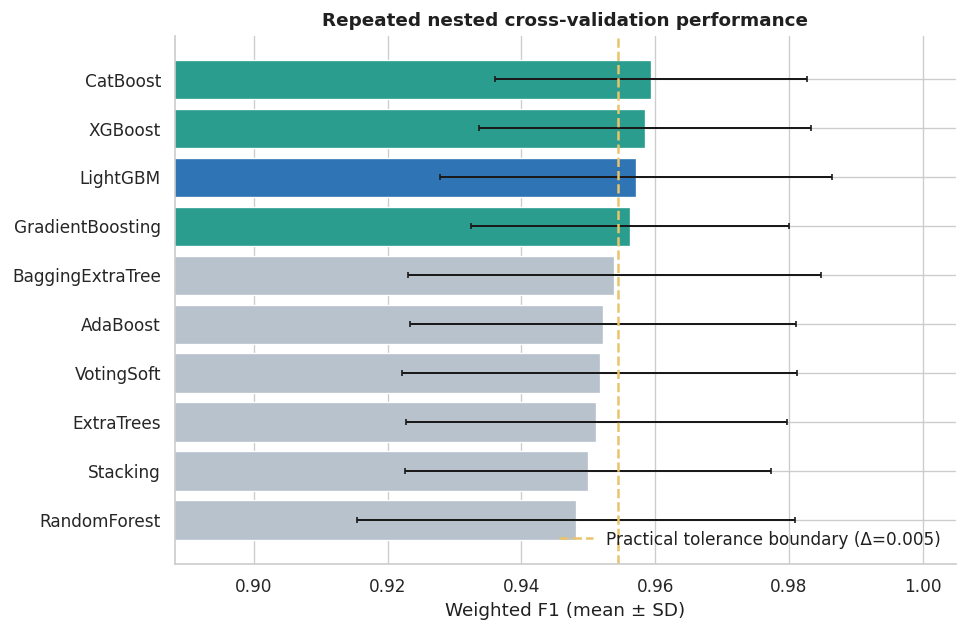

,descriptive_rank,model,Accuracy,F1_weighted,MCC,ROC_AUC,Average_precision,brier_mean,ece_mean,fit_time_mean,selected
0,1,CatBoost,0.9596 ± 0.0231,0.9594 ± 0.0233,0.9146 ± 0.0496,0.9873 ± 0.0179,0.9850 ± 0.0178,0.035385,0.066234,14.519864,False
1,2,XGBoost,0.9587 ± 0.0245,0.9585 ± 0.0248,0.9133 ± 0.0520,0.9879 ± 0.0193,0.9858 ± 0.0189,0.034332,0.062853,6.630015,False
2,3,LightGBM,0.9575 ± 0.0290,0.9572 ± 0.0293,0.9101 ± 0.0622,0.9891 ± 0.0167,0.9862 ± 0.0173,0.035404,0.071118,6.129435,True
3,4,GradientBoosting,0.9565 ± 0.0236,0.9563 ± 0.0238,0.9079 ± 0.0506,0.9873 ± 0.0161,0.9838 ± 0.0177,0.037006,0.061261,45.532362,False
4,5,BaggingExtraTree,0.9544 ± 0.0303,0.9539 ± 0.0308,0.9035 ± 0.0644,0.9875 ± 0.0127,0.9827 ± 0.0161,0.038104,0.059020,25.720954,False
5,6,AdaBoost,0.9526 ± 0.0284,0.9522 ± 0.0288,0.8998 ± 0.0609,0.9891 ± 0.0179,0.9866 ± 0.0178,0.034518,0.059669,27.329374,False
6,7,VotingSoft,0.9521 ± 0.0291,0.9517 ± 0.0295,0.8986 ± 0.0622,0.9871 ± 0.0150,0.9832 ± 0.0171,0.039021,0.065211,6.500990,False
7,8,ExtraTrees,0.9517 ± 0.0280,0.9512 ± 0.0285,0.8976 ± 0.0601,0.9860 ± 0.0147,0.9818 ± 0.0167,0.038980,0.064513,27.142036,False
8,9,Stacking,0.9504 ± 0.0269,0.9499 ± 0.0273,0.8953 ± 0.0572,0.9875 ± 0.0139,0.9836 ± 0.0160,0.037920,0.061328,35.736853,False
9,10,RandomForest,0.9486 ± 0.0322,0.9482 ± 0.0327,0.8915 ± 0.0687,0.9847 ± 0.0188,0.9808 ± 0.0197,0.041008,0.062932,54.732016,False


,criterion,direction,best,tolerance,before,after,retained
0,f1_weighted_mean,max,0.959379,0.005,10,4,CatBoost|GradientBoosting|LightGBM|XGBoost
1,mcc_mean,max,0.914574,0.010,4,4,CatBoost|GradientBoosting|LightGBM|XGBoost
2,roc_auc_mean,max,0.989096,0.005,4,4,CatBoost|GradientBoosting|LightGBM|XGBoost
3,brier_mean,min,0.034332,0.005,4,4,CatBoost|GradientBoosting|LightGBM|XGBoost


Selected model: LightGBM


In [9]:
# 8. Auditable ranking, manuscript table, and benchmarking figure
summary=fold_df.groupby("model").agg(
 accuracy_mean=("accuracy","mean"),accuracy_sd=("accuracy","std"),
 f1_weighted_mean=("f1_weighted","mean"),f1_weighted_sd=("f1_weighted","std"),
 mcc_mean=("mcc","mean"),mcc_sd=("mcc","std"),roc_auc_mean=("roc_auc","mean"),roc_auc_sd=("roc_auc","std"),
 average_precision_mean=("average_precision","mean"),average_precision_sd=("average_precision","std"),brier_mean=("brier","mean"),
 ece_mean=("ece","mean"),fit_time_mean=("fit_s","mean")).reset_index()
best_name,selection_audit=practical_select(summary)
summary["selected"]=summary.model.eq(best_name)
summary=summary.sort_values("f1_weighted_mean",ascending=False).reset_index(drop=True)
summary.insert(0,"descriptive_rank",np.arange(1,len(summary)+1))
export(summary,"table_01_repeated_nested_cv_model_summary")
export(selection_audit,"table_02_practical_tolerance_audit")

manuscript=summary.assign(
 Accuracy=summary.apply(lambda r:f'{r.accuracy_mean:.4f} ± {r.accuracy_sd:.4f}',axis=1),
 F1_weighted=summary.apply(lambda r:f'{r.f1_weighted_mean:.4f} ± {r.f1_weighted_sd:.4f}',axis=1),
 MCC=summary.apply(lambda r:f'{r.mcc_mean:.4f} ± {r.mcc_sd:.4f}',axis=1),
 ROC_AUC=summary.apply(lambda r:f'{r.roc_auc_mean:.4f} ± {r.roc_auc_sd:.4f}',axis=1),
 Average_precision=summary.apply(lambda r:f'{r.average_precision_mean:.4f} ± {r.average_precision_sd:.4f}',axis=1))
manuscript=manuscript[["descriptive_rank","model","Accuracy","F1_weighted","MCC","ROC_AUC","Average_precision","brier_mean","ece_mean","fit_time_mean","selected"]]
export(manuscript,"manuscript_table_model_comparison")

(META/"selection_rule.json").write_text(json.dumps({"tolerances":{"weighted_f1":cfg.tol_f1w,"mcc":cfg.tol_mcc,"roc_auc":cfg.tol_auc,"brier":cfg.tol_brier},
 "selected_model":best_name,"tie_break":"lowest mean search-and-fit time, then model name"},indent=2),encoding="utf-8")

plot_df=summary.sort_values("f1_weighted_mean")
colors=[PALETTE["blue"] if m==best_name else (PALETTE["teal"] if v>=summary.f1_weighted_mean.max()-cfg.tol_f1w else "#B8C2CC") for m,v in zip(plot_df.model,plot_df.f1_weighted_mean)]
fig,ax=plt.subplots(figsize=(8.2,5.4))
ax.barh(plot_df.model,plot_df.f1_weighted_mean,xerr=plot_df.f1_weighted_sd,color=colors,edgecolor="white",capsize=2)
ax.axvline(summary.f1_weighted_mean.max()-cfg.tol_f1w,color=PALETTE["gold"],ls="--",lw=1.5,label=f"Practical tolerance boundary (Δ={cfg.tol_f1w:.3f})")
ax.set(xlabel="Weighted F1 (mean ± SD)",ylabel="",title="Repeated nested cross-validation performance")
ax.set_xlim(max(0,plot_df.f1_weighted_mean.min()-.06),1.005); ax.legend(loc="lower right"); fig.tight_layout(); save_figure(fig,"figure_01_nested_cv_weighted_f1"); plt.show()
display(manuscript); display(selection_audit); print("Selected model:",best_name)


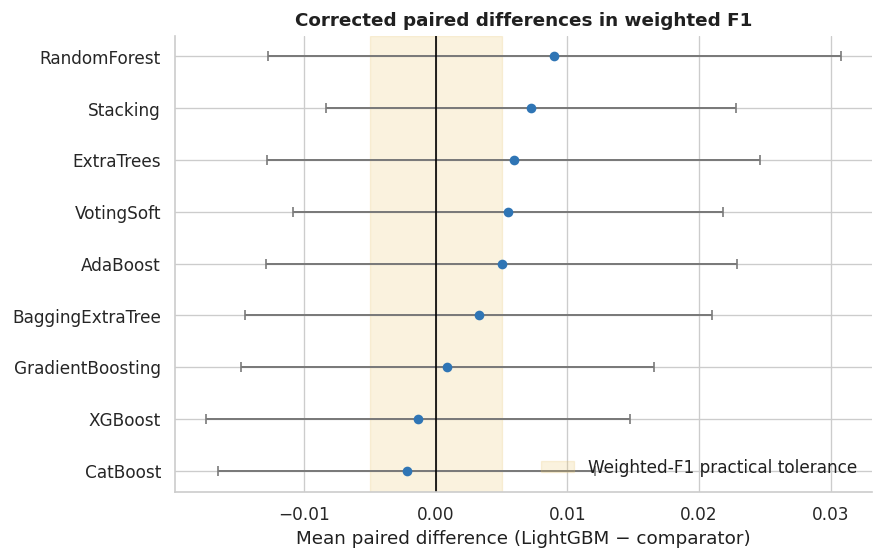

,metric,chi_square,p_value,blocks,models,interpretation
0,weighted_f1,23.253656,0.005651,50,10,Exploratory: repeated-CV blocks are not fully ...


,selected_model,comparator,mean_difference,corrected_se,ci95_low,ci95_high,t_value,p_raw,p_holm,reject_holm
0,LightGBM,AdaBoost,0.005001,0.008889,-0.012862,0.022864,0.562616,0.576261,1.0,False
1,LightGBM,BaggingExtraTree,0.003262,0.008813,-0.014449,0.020972,0.370109,0.712896,1.0,False
2,LightGBM,CatBoost,-0.002216,0.007117,-0.016518,0.012087,-0.311294,0.756897,1.0,False
3,LightGBM,ExtraTrees,0.005942,0.009317,-0.012782,0.024666,0.637774,0.526590,1.0,False
4,LightGBM,GradientBoosting,0.000886,0.007799,-0.014788,0.016560,0.113591,0.910026,1.0,False
5,LightGBM,RandomForest,0.008985,0.010829,-0.012776,0.030747,0.829746,0.410707,1.0,False
6,LightGBM,Stacking,0.007224,0.007757,-0.008364,0.022812,0.931316,0.356256,1.0,False
7,LightGBM,VotingSoft,0.005475,0.008116,-0.010835,0.021785,0.674597,0.503103,1.0,False
8,LightGBM,XGBoost,-0.001313,0.008014,-0.017417,0.014790,-0.163900,0.870484,1.0,False


In [10]:
# 9. Statistical comparison with dependence correction and multiplicity control
pivot=fold_df.pivot(index="block",columns="model",values="f1_weighted").dropna(axis=1)
stat,p_global=friedmanchisquare(*[pivot[c] for c in pivot])
friedman=pd.DataFrame([{"metric":"weighted_f1","chi_square":stat,"p_value":p_global,"blocks":len(pivot),"models":pivot.shape[1],
 "interpretation":"Exploratory: repeated-CV blocks are not fully independent; non-significance does not establish equivalence."}])
export(friedman,"table_03_friedman_repeated_cv")
test_ratio=1/(n_splits-1); comparisons=[]
for name in pivot:
 if name==best_name: continue
 d=(pivot[best_name]-pivot[name]).to_numpy(); mean=d.mean(); var=d.var(ddof=1)
 se=math.sqrt((1/len(d)+test_ratio)*var); tval=mean/se if se>0 else np.nan
 p=2*student_t.sf(abs(tval),df=len(d)-1) if np.isfinite(tval) else 1.
 comparisons.append({"selected_model":best_name,"comparator":name,"mean_difference":mean,"corrected_se":se,
  "ci95_low":mean-student_t.ppf(.975,len(d)-1)*se,"ci95_high":mean+student_t.ppf(.975,len(d)-1)*se,"t_value":tval,"p_raw":p})
paired=pd.DataFrame(comparisons)
if len(paired):
 paired["p_holm"]=multipletests(paired.p_raw,alpha=cfg.alpha,method="holm")[1]
 paired["reject_holm"]=paired.p_holm<cfg.alpha
export(paired,"table_04_nadeau_bengio_holm")

q=paired.sort_values("mean_difference"); fig,ax=plt.subplots(figsize=(7.5,4.8))
ax.errorbar(q.mean_difference,q.comparator,xerr=[q.mean_difference-q.ci95_low,q.ci95_high-q.mean_difference],fmt="o",color=PALETTE["blue"],ecolor=PALETTE["gray"],capsize=3)
ax.axvline(0,color="black",lw=1); ax.axvspan(-cfg.tol_f1w,cfg.tol_f1w,color=PALETTE["gold"],alpha=.22,label="Weighted-F1 practical tolerance")
ax.set(xlabel=f"Mean paired difference ({best_name} − comparator)",ylabel="",title="Corrected paired differences in weighted F1")
ax.legend(loc="best"); fig.tight_layout(); save_figure(fig,"figure_02_corrected_paired_differences"); plt.show()
display(friedman); display(paired)


In [11]:
# 10. FULLY NESTED OOF THRESHOLD FOR THE SAME FINAL ALGORITHM
# The algorithm selected by repeated benchmarking (best_name) remains
# fixed. Tuning and calibration are repeated inside every threshold outer fold
# without using the validation observations. The threshold therefore belongs to
# the same algorithm that is subsequently fitted to the full development set.
th_n=3 if cfg.quick_mode else cfg.threshold_outer_splits
th_cv=StratifiedKFold(th_n,shuffle=True,random_state=SEED+700)
oof=np.full(len(y_dev),np.nan); th_log=[]
for f,(tr,va) in enumerate(th_cv.split(X_dev,y_dev),1):
 Xtr,Xva=X_dev.iloc[tr],X_dev.iloc[va]; ytr=y_dev[tr]
 fitted,tuned,bp,inner_score=tune_and_calibrate(best_name,Xtr,ytr,SEED+8000*f)
 oof[va]=fitted.predict_proba(Xva)[:,1]
 th_log.append({'threshold_outer_fold':f,'fixed_algorithm':best_name,'best_params':json.dumps(bp,sort_keys=True),
                'inner_score':inner_score,'train_n':len(tr),'validation_n':len(va)})
 print(f'threshold cross-fit {f}/{th_n}: fixed algorithm={best_name}')
assert np.isfinite(oof).all(), 'Incomplete OOF predictions'
export(pd.DataFrame(th_log),'threshold_crossfit_fixed_algorithm_log')
threshold_oof=pd.DataFrame({'source_row_id':dev_ids,'observed':y_dev,'probability_oof':oof})
export(threshold_oof,'threshold_oof_predictions')
assert threshold_oof.source_row_id.is_unique and threshold_oof.probability_oof.between(0,1).all()

def threshold_table(y,p):
 out=[]
 for t in np.arange(cfg.threshold_grid_start,cfg.threshold_grid_stop+1e-12,cfg.threshold_grid_step):
  z=(p>=t).astype(int); tn,fp,fn,tp=confusion_matrix(y,z,labels=[0,1]).ravel()
  out.append({'threshold':t,'TN':tn,'FP':fp,'FN':fn,'TP':tp,'sensitivity':tp/(tp+fn),
   'specificity':tn/(tn+fp),'PPV':tp/(tp+fp) if tp+fp else np.nan,
   'NPV':tn/(tn+fn) if tn+fn else np.nan,'F1':f1_score(y,z,zero_division=0)})
 return pd.DataFrame(out)

thresholds=threshold_table(y_dev,oof)
eligible=thresholds[thresholds.sensitivity>=cfg.threshold_min_sensitivity]
if len(eligible):
 selected_threshold=float(eligible.sort_values(['specificity','F1','threshold'],ascending=[False,False,True]).iloc[0].threshold)
 threshold_status='min_sensitivity_then_specificity'
else:
 selected_threshold=float(thresholds.sort_values(['sensitivity','specificity','threshold'],ascending=[False,False,True]).iloc[0].threshold)
 threshold_status='fallback_max_sensitivity'
export(thresholds,'fully_nested_oof_thresholds_fixed_algorithm')
print('Frozen algorithm:',best_name,'| Frozen OOF threshold:',selected_threshold,threshold_status)


threshold cross-fit 1/5: fixed algorithm=LightGBM
threshold cross-fit 2/5: fixed algorithm=LightGBM
threshold cross-fit 3/5: fixed algorithm=LightGBM
threshold cross-fit 4/5: fixed algorithm=LightGBM
threshold cross-fit 5/5: fixed algorithm=LightGBM
Frozen algorithm: LightGBM | Frozen OOF threshold: 0.14 min_sensitivity_then_specificity


In [12]:
# 11. COHERENT FINAL FIT USING DEVELOPMENT DATA ONLY
# The final model is exactly the algorithm selected by repeated benchmarking.
# No second selection step is allowed to produce a different winner.
final_name=best_name
final_model,final_tuned,final_params,final_inner_score=tune_and_calibrate(final_name,X_dev,y_dev,SEED+12000)
joblib.dump(final_model,MOD/'final_calibrated_model.joblib')
frozen={'final_model':final_name,'benchmark_selected_model':best_name,'best_params':final_params,
 'final_inner_score':final_inner_score,'calibration':{'method':cfg.calibration_method,'cv':cfg.calibration_splits,'ensemble':True},
 'primary_threshold':0.50,'secondary_oof_threshold':selected_threshold,
 'threshold_rule':threshold_status,'minimum_sensitivity':cfg.threshold_min_sensitivity,
 'selection_consistency':final_name==best_name}
assert frozen['selection_consistency'], 'Final model does not match the selected algorithm'
(META/'frozen_configuration_before_holdout.json').write_text(json.dumps(frozen,indent=2),encoding='utf-8')
print(json.dumps(frozen,indent=2))


{
  "final_model": "LightGBM",
  "benchmark_selected_model": "LightGBM",
  "best_params": {
    "clf__num_leaves": 7,
    "clf__n_estimators": 300,
    "clf__learning_rate": 0.1
  },
  "final_inner_score": 0.9646472601763035,
  "calibration": {
    "method": "sigmoid",
    "cv": 3,
    "ensemble": true
  },
  "primary_threshold": 0.5,
  "secondary_oof_threshold": 0.14,
  "threshold_rule": "min_sensitivity_then_specificity",
  "minimum_sensitivity": 0.95,
  "selection_consistency": true
}


## 12. Freeze point

No holdout observation has been used above this point. The next cell is the single final opening of the locked internal holdout.


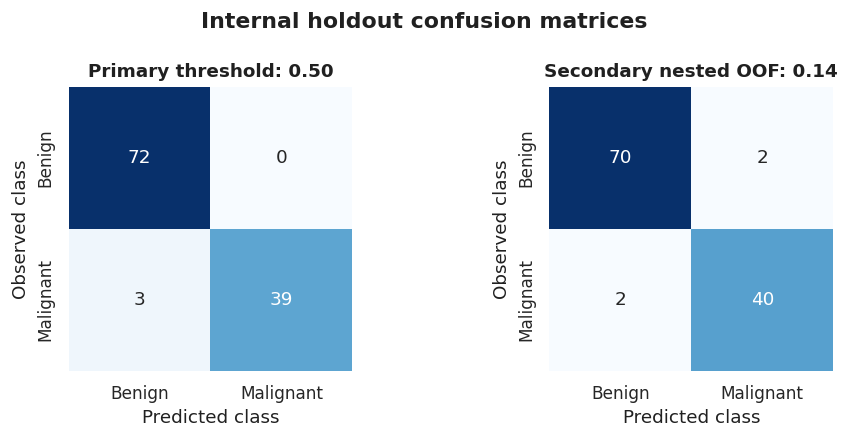

Primary threshold: 0.50 threshold= 0.5 
 [[72  0]
 [ 3 39]]
Secondary nested OOF: 0.14 threshold= 0.14 
 [[70  2]
 [ 2 40]]


,evaluation,threshold,inference_s,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,f1_weighted,mcc,kappa,roc_auc,average_precision,brier,ece
0,PRIMARY_0.50,0.50,0.020905,0.973684,0.964286,1.000000,0.928571,1.000000,0.962963,0.973465,0.944155,0.942598,0.991071,0.989058,0.026871,0.057298
1,SECONDARY_nested_OOF,0.14,0.020905,0.964912,0.962302,0.952381,0.952381,0.972222,0.952381,0.964912,0.924603,0.924603,0.991071,0.989058,0.026871,0.057298


In [13]:
# 13. SINGLE OPENING OF THE LOCKED INTERNAL HOLDOUT
t0=time.perf_counter(); hold_scores=final_model.predict_proba(X_holdout)[:,1]; inference_s=time.perf_counter()-t0
holdout_results=pd.DataFrame([
 {"evaluation":"PRIMARY_0.50","threshold":.5,"inference_s":inference_s,**metrics(y_holdout,hold_scores,.5)},
 {"evaluation":"SECONDARY_nested_OOF","threshold":selected_threshold,"inference_s":inference_s,**metrics(y_holdout,hold_scores,selected_threshold)}])
export(holdout_results,"table_05_final_internal_holdout_metrics")

cms=[]
fig,axes=plt.subplots(1,2,figsize=(8.2,3.7))
for ax,(label,t) in zip(axes,[("Primary threshold: 0.50",.5),(f"Secondary nested OOF: {selected_threshold:.2f}",selected_threshold)]):
 cm=confusion_matrix(y_holdout,(hold_scores>=t).astype(int),labels=[0,1]); cms.append((label,t,cm))
 sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",cbar=False,square=True,ax=ax,xticklabels=["Benign","Malignant"],yticklabels=["Benign","Malignant"])
 ax.set(title=label,xlabel="Predicted class",ylabel="Observed class")
fig.suptitle("Internal holdout confusion matrices",fontweight="bold"); fig.tight_layout(); save_figure(fig,"figure_03_holdout_confusion_matrices"); plt.show()
for label,t,cm in cms: print(label,"threshold=",t,"\n",cm)
holdout_predictions=pd.DataFrame({'source_row_id':holdout_ids,'observed':y_holdout,'probability':hold_scores})
export(holdout_predictions,'final_internal_holdout_predictions')
display(holdout_results)


In [14]:
# 14. Holdout uncertainty: stratified bootstrap plus exact binomial intervals
def stratified_bootstrap(y,p,t,B,seed):
 rng=np.random.default_rng(seed); groups=[np.where(y==c)[0] for c in (0,1)]; rows=[]
 for _ in range(B):
  idx=np.concatenate([rng.choice(g,len(g),replace=True) for g in groups]); rows.append(metrics(y[idx],p[idx],t))
 return pd.DataFrame(rows)
def clopper_pearson(k,n,alpha=.05):
 lo=0.0 if k==0 else beta_dist.ppf(alpha/2,k,n-k+1)
 hi=1.0 if k==n else beta_dist.ppf(1-alpha/2,k+1,n-k)
 return float(lo),float(hi)

B=200 if cfg.quick_mode else cfg.holdout_bootstrap_repetitions
all_ci=[]; exact_rows=[]; bootstrap_store={}
for label,t in [('primary_0.50',.5),('secondary_OOF',selected_threshold)]:
 boot=stratified_bootstrap(y_holdout,hold_scores,t,B,SEED+14000+(0 if label.startswith('primary') else 1))
 bootstrap_store[label]=boot; estimate=metrics(y_holdout,hold_scores,t)
 for c in boot:
  all_ci.append({'evaluation':label,'threshold':t,'metric':c,'estimate':estimate[c],'ci95_low':boot[c].quantile(.025),'ci95_high':boot[c].quantile(.975),'method':'stratified percentile bootstrap; conditional on frozen model','B':len(boot)})
 tn,fp,fn,tp=confusion_matrix(y_holdout,hold_scores>=t,labels=[0,1]).ravel()
 for metric,k,n in [('sensitivity',tp,tp+fn),('specificity',tn,tn+fp),('precision',tp,tp+fp),('NPV',tn,tn+fn)]:
  lo,hi=clopper_pearson(int(k),int(n),cfg.alpha); exact_rows.append({'evaluation':label,'threshold':t,'metric':metric,'successes':int(k),'denominator':int(n),'estimate':k/n,'ci95_low':lo,'ci95_high':hi,'method':'Clopper-Pearson exact'})
ci=pd.DataFrame(all_ci); exact_ci=pd.DataFrame(exact_rows)
export(ci,'holdout_bootstrap_ci95_both_thresholds'); export(exact_ci,'holdout_exact_binomial_ci95')
display(ci); display(exact_ci)


,evaluation,threshold,metric,estimate,ci95_low,ci95_high,method,B
0,primary_0.50,0.50,accuracy,0.973684,0.938596,1.000000,stratified percentile bootstrap; conditional o...,2000
1,primary_0.50,0.50,balanced_accuracy,0.964286,0.916667,1.000000,stratified percentile bootstrap; conditional o...,2000
2,primary_0.50,0.50,precision,1.000000,1.000000,1.000000,stratified percentile bootstrap; conditional o...,2000
3,primary_0.50,0.50,sensitivity,0.928571,0.833333,1.000000,stratified percentile bootstrap; conditional o...,2000
4,primary_0.50,0.50,specificity,1.000000,1.000000,1.000000,stratified percentile bootstrap; conditional o...,2000
5,primary_0.50,0.50,f1,0.962963,0.909091,1.000000,stratified percentile bootstrap; conditional o...,2000
6,primary_0.50,0.50,f1_weighted,0.973465,0.937229,1.000000,stratified percentile bootstrap; conditional o...,2000
7,primary_0.50,0.50,mcc,0.944155,0.871489,1.000000,stratified percentile bootstrap; conditional o...,2000
8,primary_0.50,0.50,kappa,0.942598,0.863309,1.000000,stratified percentile bootstrap; conditional o...,2000
9,primary_0.50,0.50,roc_auc,0.991071,0.973214,1.000000,stratified percentile bootstrap; conditional o...,2000


,evaluation,threshold,metric,successes,denominator,estimate,ci95_low,ci95_high,method
0,primary_0.50,0.50,sensitivity,39,42,0.928571,0.805169,0.985020,Clopper-Pearson exact
1,primary_0.50,0.50,specificity,72,72,1.000000,0.950056,1.000000,Clopper-Pearson exact
2,primary_0.50,0.50,precision,39,39,1.000000,0.909749,1.000000,Clopper-Pearson exact
3,primary_0.50,0.50,NPV,72,75,0.960000,0.887523,0.991674,Clopper-Pearson exact
4,secondary_OOF,0.14,sensitivity,40,42,0.952381,0.838358,0.994180,Clopper-Pearson exact
5,secondary_OOF,0.14,specificity,70,72,0.972222,0.903233,0.996618,Clopper-Pearson exact
6,secondary_OOF,0.14,precision,40,42,0.952381,0.838358,0.994180,Clopper-Pearson exact
7,secondary_OOF,0.14,NPV,70,72,0.972222,0.903233,0.996618,Clopper-Pearson exact


In [15]:
# 15. Sensitivity to development-sample variability — hyperparameters and thresholds frozen
D=3 if cfg.quick_mode else cfg.development_bootstrap_repetitions
rng=np.random.default_rng(SEED+15000); dev_rows=[]
for b in range(D):
 idx=np.concatenate([rng.choice(np.where(y_dev==c)[0],np.sum(y_dev==c),replace=True) for c in (0,1)])
 Xb=X_dev.iloc[idx]; yb=y_dev[idx]
 cv=StratifiedKFold(2 if cfg.quick_mode else cfg.calibration_splits,shuffle=True,random_state=SEED+17000+b)
 m=calibrator(clone(final_tuned),cv).fit(Xb,yb); p=m.predict_proba(X_holdout)[:,1]
 for label,t in [('primary_0.50',.5),('secondary_OOF',selected_threshold)]:
  dev_rows.append({'development_bootstrap':b+1,'evaluation':label,'threshold':t,'algorithm':final_name,'hyperparameters_frozen':True,**metrics(y_holdout,p,t)})
 if (b+1)%10==0 or b==0: print(f'development bootstrap {b+1}/{D}')
dev_unc=pd.DataFrame(dev_rows); export(dev_unc,'development_pipeline_sensitivity_both_thresholds')
dev_ci=[]
excluded={'development_bootstrap','evaluation','threshold','algorithm','hyperparameters_frozen'}
for label,g in dev_unc.groupby('evaluation'):
 for c in [x for x in g.columns if x not in excluded]:
  dev_ci.append({'evaluation':label,'metric':c,'median':g[c].median(),'p2_5':g[c].quantile(.025),'p97_5':g[c].quantile(.975),'interpretation':'training-sample perturbation conditional on frozen algorithm/hyperparameters/threshold; not external validation'})
dev_ci=pd.DataFrame(dev_ci); export(dev_ci,'development_uncertainty_summary_both_thresholds'); display(dev_ci)


development bootstrap 1/100
development bootstrap 10/100
development bootstrap 20/100
development bootstrap 30/100
development bootstrap 40/100
development bootstrap 50/100
development bootstrap 60/100
development bootstrap 70/100
development bootstrap 80/100
development bootstrap 90/100
development bootstrap 100/100


,evaluation,metric,median,p2_5,p97_5,interpretation
0,primary_0.50,accuracy,0.956140,0.933991,0.973684,training-sample perturbation conditional on fr...
1,primary_0.50,balanced_accuracy,0.945437,0.915625,0.964286,training-sample perturbation conditional on fr...
2,primary_0.50,precision,1.000000,0.950579,1.000000,training-sample perturbation conditional on fr...
3,primary_0.50,sensitivity,0.904762,0.844643,0.952381,training-sample perturbation conditional on fr...
4,primary_0.50,specificity,1.000000,0.972222,1.000000,training-sample perturbation conditional on fr...
5,primary_0.50,f1,0.938272,0.904318,0.962963,training-sample perturbation conditional on fr...
6,primary_0.50,f1_weighted,0.955776,0.932918,0.973465,training-sample perturbation conditional on fr...
7,primary_0.50,mcc,0.907605,0.858507,0.944155,training-sample perturbation conditional on fr...
8,primary_0.50,kappa,0.904330,0.854303,0.942598,training-sample perturbation conditional on fr...
9,primary_0.50,roc_auc,0.989418,0.979167,0.997354,training-sample perturbation conditional on fr...


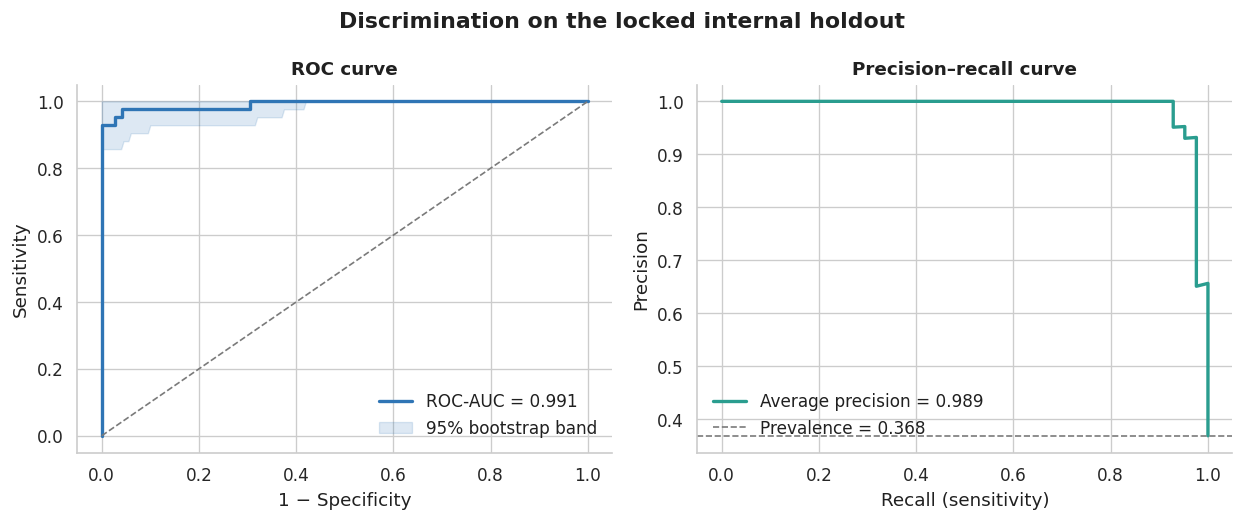

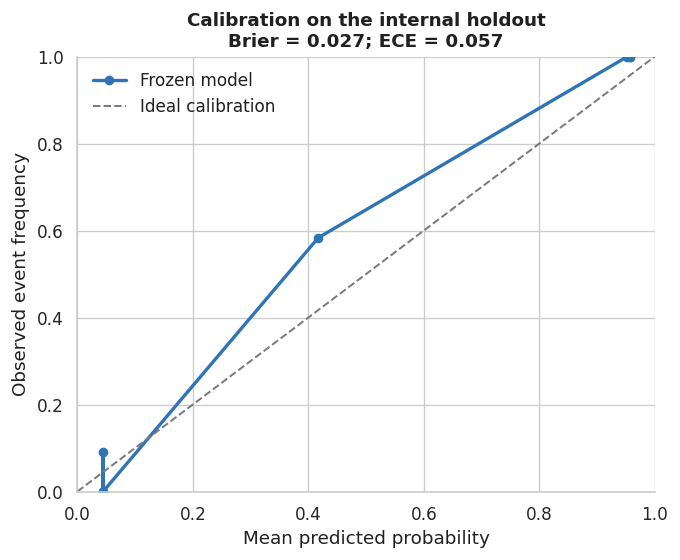

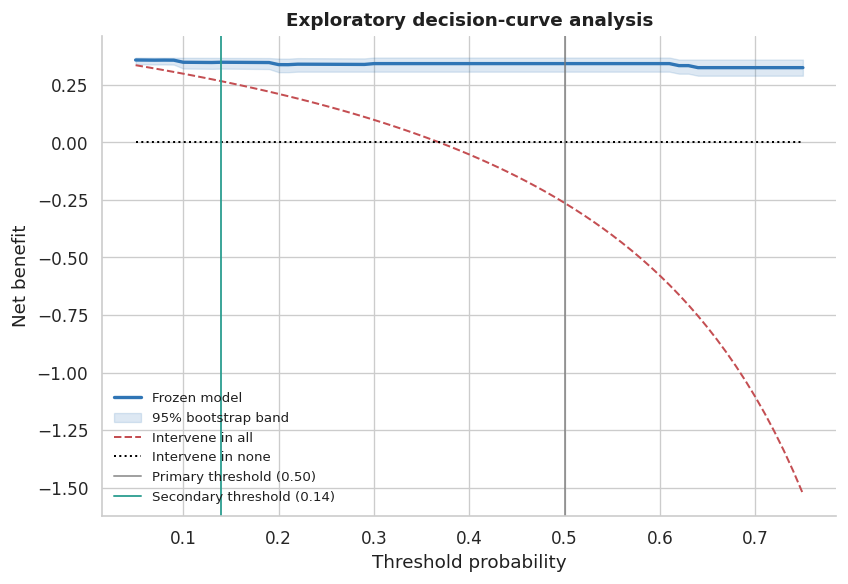

In [16]:
# 16. FINAL INTERNAL CURVES, CALIBRATION, AND EXPLORATORY DCA
auc_value=roc_auc_score(y_holdout,hold_scores); ap_value=average_precision_score(y_holdout,hold_scores)
fpr,tpr,_=roc_curve(y_holdout,hold_scores); precision,recall,_=precision_recall_curve(y_holdout,hold_scores)

# Stratified-bootstrap ROC band, conditional on the frozen model.
fpr_grid=np.linspace(0,1,201); B_roc=100 if cfg.quick_mode else cfg.roc_bootstrap_repetitions
rng=np.random.default_rng(SEED+17500); groups=[np.where(y_holdout==c)[0] for c in (0,1)]; tprs=[]
for _ in range(B_roc):
 idx=np.concatenate([rng.choice(g,len(g),replace=True) for g in groups]); bfpr,btpr,_=roc_curve(y_holdout[idx],hold_scores[idx])
 tprs.append(np.interp(fpr_grid,bfpr,btpr))
tprs=np.asarray(tprs); roc_lo,roc_hi=np.quantile(tprs,[.025,.975],axis=0)

fig,ax=plt.subplots(1,2,figsize=(10.5,4.4))
ax[0].plot(fpr,tpr,color=PALETTE["blue"],lw=2,label=f"ROC-AUC = {auc_value:.3f}")
ax[0].fill_between(fpr_grid,roc_lo,roc_hi,color=PALETTE["blue"],alpha=.16,label="95% bootstrap band")
ax[0].plot([0,1],[0,1],"--",color=PALETTE["gray"],lw=1); ax[0].set(xlabel="1 − Specificity",ylabel="Sensitivity",title="ROC curve"); ax[0].legend(loc="lower right")
ax[1].plot(recall,precision,color=PALETTE["teal"],lw=2,label=f"Average precision = {ap_value:.3f}")
ax[1].axhline(y_holdout.mean(),ls="--",color=PALETTE["gray"],lw=1,label=f"Prevalence = {y_holdout.mean():.3f}")
ax[1].set(xlabel="Recall (sensitivity)",ylabel="Precision",title="Precision–recall curve"); ax[1].legend(loc="lower left")
fig.suptitle("Discrimination on the locked internal holdout",fontweight="bold"); fig.tight_layout(); save_figure(fig,"figure_04_holdout_roc_pr"); plt.show()

frac,meanp=calibration_curve(y_holdout,hold_scores,n_bins=10,strategy=cfg.ece_strategy)
fig,ax=plt.subplots(figsize=(5.8,4.8)); ax.plot(meanp,frac,"o-",color=PALETTE["blue"],lw=2,label="Frozen model"); ax.plot([0,1],[0,1],"--",color=PALETTE["gray"],label="Ideal calibration")
ax.set(xlabel="Mean predicted probability",ylabel="Observed event frequency",title=f"Calibration on the internal holdout\nBrier = {brier_score_loss(y_holdout,hold_scores):.3f}; ECE = {ece(y_holdout,hold_scores,cfg.ece_bins,cfg.ece_strategy):.3f}")
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.legend(loc="upper left"); fig.tight_layout(); save_figure(fig,"figure_05_holdout_calibration"); plt.show()

def net_benefit(y,p,grid):
 out=[]; n=len(y); prev=y.mean()
 for t in grid:
  tn,fp,fn,tp=confusion_matrix(y,p>=t,labels=[0,1]).ravel()
  out.append({"threshold":t,"model":tp/n-fp/n*t/(1-t),"treat_all":prev-(1-prev)*t/(1-t),"treat_none":0.})
 return pd.DataFrame(out)
grid=np.arange(.05,.76,.01); dca_point=net_benefit(y_holdout,hold_scores,grid)
B_dca=100 if cfg.quick_mode else cfg.dca_bootstrap_repetitions; rng=np.random.default_rng(SEED+18000); curves=[]
for b in range(B_dca):
 idx=np.concatenate([rng.choice(g,len(g),replace=True) for g in groups]); q=net_benefit(y_holdout[idx],hold_scores[idx],grid); q["bootstrap"]=b; curves.append(q[["threshold","model","bootstrap"]])
dca_boot=pd.concat(curves,ignore_index=True); bands=dca_boot.groupby("threshold").model.quantile([.025,.975]).unstack().reset_index().rename(columns={.025:"ci95_low",.975:"ci95_high"})
dca=dca_point.merge(bands,on="threshold"); export(dca,"table_08_holdout_dca_bootstrap")
fig,ax=plt.subplots(figsize=(7.2,5.0)); ax.plot(dca.threshold,dca.model,label="Frozen model",lw=2,color=PALETTE["blue"]); ax.fill_between(dca.threshold,dca.ci95_low,dca.ci95_high,color=PALETTE["blue"],alpha=.16,label="95% bootstrap band")
ax.plot(dca.threshold,dca.treat_all,"--",color=PALETTE["red"],label="Intervene in all"); ax.plot(dca.threshold,dca.treat_none,":",color="black",label="Intervene in none")
ax.axvline(.5,color=PALETTE["gray"],alpha=.7,label="Primary threshold (0.50)"); ax.axvline(selected_threshold,color=PALETTE["teal"],alpha=.9,label=f"Secondary threshold ({selected_threshold:.2f})")
ax.set(xlabel="Threshold probability",ylabel="Net benefit",title="Exploratory decision-curve analysis"); ax.legend(loc="best",fontsize=8); fig.tight_layout(); save_figure(fig,"figure_06_holdout_dca"); plt.show()


PermutationExplainer explainer: 51it [01:04,  1.43s/it]


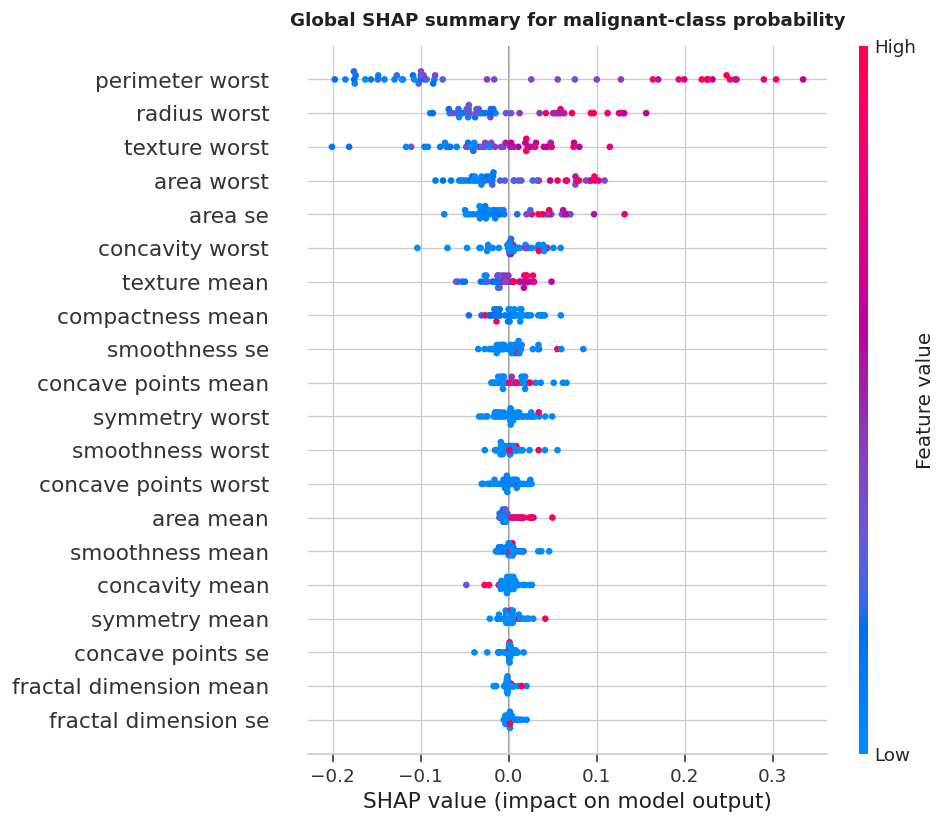

,feature,mean_abs_shap
22,perimeter worst,0.151381
20,radius worst,0.054357
21,texture worst,0.049307
23,area worst,0.047374
13,area se,0.035846
26,concavity worst,0.021061
1,texture mean,0.018585
5,compactness mean,0.015868
14,smoothness se,0.015601
7,concave points mean,0.014878


LIME figure suppressed: local fidelity R²=0.0777 is below the prespecified 0.50 threshold.


,condition,weight,instance_index,observed_class,predicted_probability_malignant,local_fidelity_R2,interpretability_status
0,texture worst <= 21.49,-0.158108,16,1,0.044408,0.077705,not_reliable_for_interpretation
1,17.86 < area se <= 24.87,-0.058258,16,1,0.044408,0.077705,not_reliable_for_interpretation
2,texture mean <= 16.34,-0.057658,16,1,0.044408,0.077705,not_reliable_for_interpretation
3,683.40 < area worst <= 1122.50,0.057450,16,1,0.044408,0.077705,not_reliable_for_interpretation
4,compactness mean > 7.33,-0.056293,16,1,0.044408,0.077705,not_reliable_for_interpretation
5,concave points worst <= 1.58,-0.043507,16,1,0.044408,0.077705,not_reliable_for_interpretation
6,1.38 < smoothness worst <= 1.62,0.039388,16,1,0.044408,0.077705,not_reliable_for_interpretation
7,2.55 < symmetry worst <= 2.87,-0.036714,16,1,0.044408,0.077705,not_reliable_for_interpretation
8,4.48 < smoothness se <= 5.88,-0.030846,16,1,0.044408,0.077705,not_reliable_for_interpretation
9,concavity mean > 6.07,-0.029805,16,1,0.044408,0.077705,not_reliable_for_interpretation


102

In [17]:
# 17. POST HOC EXPLAINABILITY: SHAP + FIDELITY-GATED LIME
explainability_status={"SHAP":"not_run","LIME":"not_run"}
if cfg.run_explainability:
 try:
  import shap
  background=X_dev.sample(min(80,len(X_dev)),random_state=SEED)
  explained=X_holdout.sample(min(50,len(X_holdout)),random_state=SEED+1)
  predict_fn=lambda z: final_model.predict_proba(pd.DataFrame(z,columns=X_dev.columns))[:,1]
  explainer=shap.Explainer(predict_fn,background,algorithm="permutation",seed=SEED)
  sv=explainer(explained)
  feature_labels=[c.replace("_"," ") for c in explained.columns]
  shap.summary_plot(sv,explained,feature_names=feature_labels,show=False,max_display=20,color_bar_label="Feature value")
  fig=plt.gcf(); fig.set_size_inches(8.2,7.0); plt.title("Global SHAP summary for malignant-class probability",fontweight="bold",pad=12); plt.tight_layout(); save_figure(fig,"figure_07_shap_global_summary"); plt.show()
  shap_importance=pd.DataFrame({"feature":feature_labels,"mean_abs_shap":np.abs(np.asarray(sv.values)).mean(axis=0)}).sort_values("mean_abs_shap",ascending=False)
  export(shap_importance,"table_09_shap_global_importance"); np.save(META/"shap_values.npy",np.asarray(sv.values)); explainability_status["SHAP"]="valid_posthoc_global_explanation"; display(shap_importance.head(20))
 except Exception as e: explainability_status["SHAP"]=f"failed: {e!r}"; print("[SHAP warning]",repr(e))

 try:
  from lime.lime_tabular import LimeTabularExplainer
  if not all(pd.api.types.is_numeric_dtype(X_dev[c]) for c in X_dev):
   explainability_status["LIME"]="omitted_categorical_predictors_require_separate_protocol"
  else:
   malignant=np.where(y_holdout==1)[0]; false_negative=malignant[hold_scores[malignant]<.5]
   idx=int(false_negative[0]) if len(false_negative) else int(malignant[np.argmin(hold_scores[malignant])])
   lime=LimeTabularExplainer(X_dev.to_numpy(),feature_names=[c.replace("_"," ") for c in X_dev.columns],class_names=["Benign","Malignant"],mode="classification",random_state=SEED,discretize_continuous=True)
   pred=lambda z: final_model.predict_proba(pd.DataFrame(z,columns=X_dev.columns))
   exp=lime.explain_instance(X_holdout.iloc[idx].to_numpy(),pred,num_features=min(15,X_dev.shape[1]),num_samples=20000)
   fidelity=float(exp.score); lime_df=pd.DataFrame(exp.as_list(label=1),columns=["condition","weight"])
   lime_df["instance_index"]=idx; lime_df["observed_class"]=int(y_holdout[idx]); lime_df["predicted_probability_malignant"]=float(hold_scores[idx]); lime_df["local_fidelity_R2"]=fidelity
   lime_df["interpretability_status"]=np.where(fidelity>=cfg.lime_min_fidelity,"retained","not_reliable_for_interpretation")
   export(lime_df,"table_10_lime_rule_based_posthoc_error_case")
   if fidelity>=cfg.lime_min_fidelity:
    q=lime_df.sort_values("weight"); fig,ax=plt.subplots(figsize=(7.5,5.4)); ax.barh(q.condition,q.weight,color=[PALETTE["teal"] if x>0 else PALETTE["red"] for x in q.weight]); ax.axvline(0,color="black",lw=.8)
    ax.set(xlabel="Local surrogate weight",ylabel="",title=f"LIME explanation of rule-based post hoc error case (R²={fidelity:.3f})"); fig.tight_layout(); save_figure(fig,"figure_08_lime_local_explanation"); plt.show(); explainability_status["LIME"]="retained_fidelity_threshold_met"
   else:
    explainability_status["LIME"]=f"not_interpretable_low_fidelity_R2_{fidelity:.4f}"
    print(f"LIME figure suppressed: local fidelity R²={fidelity:.4f} is below the prespecified {cfg.lime_min_fidelity:.2f} threshold.")
   display(lime_df)
 except Exception as e: explainability_status["LIME"]=f"failed: {e!r}"; print("[LIME warning]",repr(e))
(META/"explainability_status.json").write_text(json.dumps(explainability_status,indent=2),encoding="utf-8")


In [21]:
# 18. INTEGRITY CHECKS, AUTOMATED ENGLISH REPORT, AND RESULT PACKAGE
checks={
 "split_disjoint":set(dev_ids).isdisjoint(set(holdout_ids)),
 "split_complete":len(dev_ids)+len(holdout_ids)==len(y_all),
 "stacking_architecture_passed":audit_stacking_architecture(build_model("Stacking",X_dev,SEED)),
 "benchmark_probabilities_valid":bool(benchmark_oof.probability.between(0,1).all()),
 "threshold_oof_one_per_development_record":threshold_oof.source_row_id.is_unique and len(threshold_oof)==len(y_dev),
 "threshold_oof_probabilities_valid":bool(threshold_oof.probability_oof.between(0,1).all()),
 "holdout_predictions_one_per_record":holdout_predictions.source_row_id.is_unique and len(holdout_predictions)==len(y_holdout),
 "selected_final_algorithm_consistent":final_name==best_name,
 "both_threshold_ci_available":set(ci.evaluation)=={"primary_0.50","secondary_OOF"},
 "exact_binomial_ci_available":set(exact_ci.metric)>={ "sensitivity","specificity"},
 "all_ten_models_present":set(fold_df.model)==set(MODEL_NAMES),
 "benchmark_candidates_calibrated":bool(fold_df.calibrated.all()),
 "validation_scope":"locked internal holdout only"
}
required=[k for k,v in checks.items() if k!="validation_scope"]
failed=[k for k in required if not bool(checks[k])]
if failed: raise AssertionError(f"Quality gates failed: {failed}")
checks["all_required_gates_passed"]=True
(META/"quality_checks.json").write_text(json.dumps(checks,indent=2),encoding="utf-8")

primary=holdout_results.loc[holdout_results.evaluation.str.startswith("PRIMARY")].iloc[0]
secondary=holdout_results.loc[holdout_results.evaluation.str.startswith("SECONDARY")].iloc[0]
report=f"""# Automated internal-evaluation technical report

## Analysis design
- Development sample: **{len(y_dev)}**; locked internal holdout: **{len(y_holdout)}**.
- Benchmarking: **{cfg.outer_splits}-fold \u00d7 {cfg.outer_repeats}-repeat nested cross-validation**.
- Selected and final algorithm: **{final_name}**, chosen by prespecified practical tolerances and computational tie-break.
- Global Friedman test: \u03c7\u00b2 = **{stat:.3f}**, p = **{p_global:.4f}**. This does not establish equivalence.

## Final locked internal-holdout evaluation
- Primary threshold **0.50**: accuracy {primary.accuracy:.4f}, sensitivity {primary.sensitivity:.4f}, specificity {primary.specificity:.4f}, weighted F1 {primary.f1_weighted:.4f}, MCC {primary.mcc:.4f}.
- Secondary fully nested OOF threshold **{selected_threshold:.2f}**: accuracy {secondary.accuracy:.4f}, sensitivity {secondary.sensitivity:.4f}, specificity {secondary.specificity:.4f}, weighted F1 {secondary.f1_weighted:.4f}, MCC {secondary.mcc:.4f}.
- Threshold-independent performance: ROC-AUC {primary.roc_auc:.4f}, average precision {primary.average_precision:.4f}, Brier score {primary.brier:.4f}, ECE {primary.ece:.4f}.

## Interpretation constraints
- The holdout is internal; these findings do not demonstrate external transportability, prospective clinical utility, or causal effects.
- DCA is exploratory and must be reassessed under setting-specific prevalence and utilities.
- SHAP and LIME are post hoc. LIME is reportable only when its local surrogate fidelity reaches R\u00b2 \u2265 {cfg.lime_min_fidelity:.2f}.
- Current explainability status: {json.dumps(explainability_status)}.
"""
(OUT/"TECHNICAL_RESULTS_REPORT.md").write_text(report,encoding="utf-8"); print(report)

readme="""# Output package\n\n- `tables/`: raw CSV and formatted Excel tables.\n- `figures/`: 600-dpi PNG, vector PDF, and SVG figures.\n- `models/`: frozen calibrated model.\n- `metadata/`: configuration, versions, hashes, frozen decisions, integrity checks, and explainability status.\n- `TECHNICAL_RESULTS_REPORT.md`: automated English results summary.\n"""
(OUT/"README.md").write_text(readme,encoding="utf-8")

# Automated manuscript-oriented Word report (English).
try:
 from docx import Document
 from docx.shared import Inches,Pt,RGBColor
 from docx.enum.text import WD_ALIGN_PARAGRAPH
 report_doc=Document(); section=report_doc.sections[0]
 section.top_margin=section.bottom_margin=Inches(.8); section.left_margin=section.right_margin=Inches(.8)
 normal=report_doc.styles["Normal"]; normal.font.name="Arial"; normal.font.size=Pt(10)
 title=report_doc.add_heading("WDBC ensemble benchmarking \u2014 technical results",0); title.alignment=WD_ALIGN_PARAGRAPH.CENTER
 p=report_doc.add_paragraph("Leakage-resistant repeated nested validation with a locked internal holdout"); p.alignment=WD_ALIGN_PARAGRAPH.CENTER
 report_doc.add_heading("Analysis design",1)
 report_doc.add_paragraph(f"The analytical cohort contained {len(y_all)} observations. Development comprised {len(y_dev)} observations and the locked internal holdout comprised {len(y_holdout)} observations. Model benchmarking used {cfg.outer_splits}-fold cross-validation repeated {cfg.outer_repeats} times, with hyperparameter tuning repeated inside every outer training partition.")
 report_doc.add_heading("Repeated nested cross-validation",1)
 report_doc.add_paragraph(f"{final_name} was selected by the prespecified practical-tolerance hierarchy and computational tie-break. The Friedman test was exploratory (chi-square={stat:.3f}, p={p_global:.4f}) and did not establish statistical superiority or equivalence.")
 t=report_doc.add_table(rows=1,cols=7); t.style="Light Shading Accent 1"
 for c,v in zip(t.rows[0].cells,["Model","Weighted F1","MCC","ROC-AUC","Average precision","Brier","Time (s)"]): c.text=v
 for _,r in summary.iterrows():
  cells=t.add_row().cells; vals=[r.model,f"{r.f1_weighted_mean:.4f} \u00b1 {r.f1_weighted_sd:.4f}",f"{r.mcc_mean:.4f}",f"{r.roc_auc_mean:.4f}",f"{r.average_precision_mean:.4f}",f"{r.brier_mean:.4f}",f"{r.fit_time_mean:.2f}"]
  for c,v in zip(cells,vals): c.text=str(v)
 if (FIG/"figure_01_nested_cv_weighted_f1.png").exists(): report_doc.add_picture(str(FIG/"figure_01_nested_cv_weighted_f1.png"),width=Inches(6.5))
 report_doc.add_heading("Locked internal-holdout evaluation",1)
 report_doc.add_paragraph(f"At the primary 0.50 threshold, sensitivity was {primary.sensitivity:.4f} and specificity was {primary.specificity:.4f}. At the secondary fully nested OOF threshold ({selected_threshold:.2f}), sensitivity was {secondary.sensitivity:.4f} and specificity was {secondary.specificity:.4f}. This secondary operating point remains provisional and requires external validation.")
 t=report_doc.add_table(rows=1,cols=7); t.style="Light Shading Accent 1"
 for c,v in zip(t.rows[0].cells,["Evaluation","Accuracy","Sensitivity","Specificity","Weighted F1","MCC","Threshold"]): c.text=v
 for _,r in holdout_results.iterrows():
  cells=t.add_row().cells; vals=[r.evaluation,f"{r.accuracy:.4f}",f"{r.sensitivity:.4f}",f"{r.specificity:.4f}",f"{r.f1_weighted:.4f}",f"{r.mcc:.4f}",f"{r.threshold:.2f}"]
  for c,v in zip(cells,vals): c.text=str(v)
 for fig_name in ["figure_03_holdout_confusion_matrices.png","figure_04_holdout_roc_pr.png","figure_05_holdout_calibration.png","figure_06_holdout_dca.png","figure_07_shap_global_summary.png"]:
  fp=FIG/fig_name
  if fp.exists(): report_doc.add_picture(str(fp),width=Inches(6.4))
 report_doc.add_heading("Interpretation limits",1)
 report_doc.add_paragraph("These findings establish internal performance only. They do not demonstrate external transportability, prospective clinical utility, or causal effects. Decision-curve and explainability analyses are post hoc. LIME is suppressed when its local surrogate fidelity is below the prespecified threshold.")
 report_doc.save(OUT/"PUBLICATION_RESULTS_REPORT.docx")
except Exception as e: print("[Word report warning]",repr(e))

artifact_rows=[]
for fp in sorted(x for x in OUT.rglob("*") if x.is_file()):
 artifact_rows.append({"relative_path":str(fp.relative_to(OUT)),"bytes":fp.stat().st_size,"sha256":sha256(fp.read_bytes())})
export(pd.DataFrame(artifact_rows),"artifact_checksum_manifest")
zip_path=shutil.make_archive(cfg.output_dir,"zip",root_dir=cfg.output_dir); print("Result package:",zip_path)
if IN_COLAB: files.download(zip_path)

# Automated internal-evaluation technical report

## Analysis design
- Development sample: **455**; locked internal holdout: **114**.
- Benchmarking: **10-fold × 5-repeat nested cross-validation**.
- Selected and final algorithm: **LightGBM**, chosen by prespecified practical tolerances and computational tie-break.
- Global Friedman test: χ² = **23.254**, p = **0.0057**. This does not establish equivalence.

## Final locked internal-holdout evaluation
- Primary threshold **0.50**: accuracy 0.9737, sensitivity 0.9286, specificity 1.0000, weighted F1 0.9735, MCC 0.9442.
- Secondary fully nested OOF threshold **0.14**: accuracy 0.9649, sensitivity 0.9524, specificity 0.9722, weighted F1 0.9649, MCC 0.9246.
- Threshold-independent performance: ROC-AUC 0.9911, average precision 0.9891, Brier score 0.0269, ECE 0.0573.

## Interpretation constraints
- The holdout is internal; these findings do not demonstrate external transportability, prospective clinical utility, or causal effects.
- DCA is

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>